# 04b · Label efficiency (C3)

**Purpose.** On GasWindTunnel, train with 10%, 25%, 50% and 100% of each training fold and plot macro F1 against the fraction of labels, one line per representation.

**Inputs**
- GasWindTunnel `X_signals.npy` (600, 72, 1500) + `meta.csv`; training fold of 480 → 48 / 120 / 240 / 480 samples

**Outputs**
- `results/04b_label_efficiency.csv`
- `report/figures/` label efficiency plot

## Colab setup
Run this first on Google Colab (Runtime → Change runtime type → **GPU**). Before running, upload
**`results.zip`** (results of notebooks 01-03) to `/content` with the Files panel on the left. The cell clones the
repo, downloads the processed data from the shared Drive folder, unpacks the results, and moves into this
notebook's folder so the rest runs unchanged. On a laptop it does nothing.

In [1]:
import glob
import os
import shutil
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
REPO = "/content/gas-repr-guide"
REPO_URL = "https://github.com/YasserAlbogami/gas-repr-guide.git"
DATA_URL = "https://drive.google.com/drive/folders/1rNIcZkHDFhH2dMVq8TgNWt_0IH2yw2_I"   # processed data (Yasser)
DATA_DIRS = ["gas_wind_tunnel", "everyday_scents"]

if IN_COLAB:
    # 1. code (src/). Tried in this order:
    #    a) clone the GitHub repo (works when the repo is public)
    #    b) clone with a GitHub token saved in Colab Secrets (key icon on the left) as GITHUB_TOKEN
    #    c) src.zip uploaded to /content (Files panel on the left)
    if not os.path.exists(f"{REPO}/src"):
        env = dict(os.environ, GIT_TERMINAL_PROMPT="0")           # fail instead of asking for a password
        ok = subprocess.run(["git", "clone", "-q", REPO_URL, REPO], env=env).returncode == 0
        if not ok:
            token = None
            try:
                from google.colab import userdata
                token = userdata.get("GITHUB_TOKEN")
            except Exception:
                pass
            if token:
                url = REPO_URL.replace("https://", f"https://{token}@")
                ok = subprocess.run(["git", "clone", "-q", url, REPO], env=env).returncode == 0
        if not ok and os.path.exists("/content/src.zip"):
            os.makedirs(f"{REPO}/notebooks/03_encoder", exist_ok=True)
            shutil.unpack_archive("/content/src.zip", REPO)
            ok = True
        if not ok:
            raise RuntimeError("Could not get the code: the repo is private. Make it public, or add GITHUB_TOKEN "
                               "in Colab Secrets, or upload src.zip to /content, then run this cell again.")
    elif os.path.exists(f"{REPO}/.git"):
        subprocess.run(["git", "-C", REPO, "pull", "-q"], check=False)
    os.makedirs(f"{REPO}/results", exist_ok=True)

    # 2. processed data (only downloaded once per Colab session)
    processed = f"{REPO}/data/processed"
    if not all(os.path.exists(f"{processed}/{d}/X_signals.npy") for d in DATA_DIRS):
        import gdown
        tmp = "/content/processed_download"
        gdown.download_folder(DATA_URL, output=tmp, quiet=False)
        for d in DATA_DIRS:
            found = glob.glob(f"{tmp}/**/{d}", recursive=True)
            assert found, f"folder {d} not found in the Drive download"
            shutil.copytree(found[0], f"{processed}/{d}", dirs_exist_ok=True)
    for d in DATA_DIRS:
        files = sorted(os.listdir(f"{processed}/{d}"))
        print(d, files)
        for f in ["X_signals.npy", "meta.csv", "info.json"]:
            assert f in files, f"{d}/{f} is missing"

    # 2b. results of the earlier notebooks (01, 02, 03 and the 04 ones already run), from results.zip
    #     uploaded to /content (Files panel on the left). The zip holds a results/ folder (+ report/tables/).
    if os.path.exists("/content/results.zip"):
        shutil.unpack_archive("/content/results.zip", REPO)
    have = sorted(os.path.basename(f) for f in glob.glob(f"{REPO}/results/*.csv"))
    print("results:", have)
    main = ["01a_gwt_raw", "01b_es_raw", "02b_gwt_handcrafted", "02c_es_handcrafted",
            "03a_gwt_encoder", "03b_es_encoder", "03c_end_to_end_reference"]
    missing = [n for n in main if f"{n}.csv" not in have]
    assert not missing, f"upload results.zip to /content first (missing: {missing})"

    # 3. run the rest of the notebook from its own folder, as on a laptop (so ../.. = project root)
    os.chdir(f"{REPO}/notebooks/04_comparisons")

    import torch
    print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available()
          else "NONE, switch on Runtime > Change runtime type > GPU")

In [2]:
import sys
sys.path.append("../..")          # project root, so that `import src` works

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("../..")
from src.cv import load_baseline_level, load_processed, precomputed, run_cv, save_results
from src.features.encoder import encoder_builder
from src.features.handcrafted import handcrafted_features
from src.features.raw import raw_features

DATASET = "gwt"
TASK = "multi"
FRACTIONS = [0.10, 0.25, 0.50]     # 100% is read from the main results (01a, 02b, 03a)
NAME = "04b_label_efficiency"
FIG = ROOT / "report/figures"

X, meta, info = load_processed(DATASET)                            # (600, 72, 1500)
levels = load_baseline_level(DATASET)                              # (600, 72)
F_raw = raw_features(X, 100)                                       # (600, 7200)
F_hand = handcrafted_features(X, levels, info["n_base"], info["exposure_end"])   # (600, 864)

## C3: train on 10%, 25%, 50% of each training fold
The subsample is stratified and drawn **from the training fold only**; the test fold is unchanged.
The encoder (R3) is retrained on the smaller training set.

In [3]:
runs = [("R1_raw", F_raw, precomputed), ("R2_handcrafted", F_hand, precomputed),
        ("R3_encoder", X, encoder_builder(n_out=32))]
parts = []
for frac in FRACTIONS:
    for rep, data, builder in runs:
        s, _ = run_cv(data, meta, DATASET, TASK, rep, builder, train_fraction=frac, verbose=False)
        parts.append(s)
        print(f"{frac:.2f} {rep}: " + "  ".join(f"{h} {v:.3f}" for h, v in s.groupby("head")["macro_f1"].mean().items()))
scores = pd.concat(parts, ignore_index=True)
save_results(scores, None, NAME)

0.10 R1_raw: logreg 0.692  mlp 0.587  rf 0.864  svm 0.613


0.10 R2_handcrafted: logreg 0.839  mlp 0.715  rf 0.969  svm 0.659


/Users/saeedal-asiri/Desktop/data analytics/gas-repr-guide/.venv/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


/Users/saeedal-asiri/Desktop/data analytics/gas-repr-guide/.venv/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


/Users/saeedal-asiri/Desktop/data analytics/gas-repr-guide/.venv/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


/Users/saeedal-asiri/Desktop/data analytics/gas-repr-guide/.venv/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


... (14 outputs left out)

0.25 R3_encoder: logreg 0.919  mlp 0.841  rf 0.964  svm 0.865


0.50 R1_raw: logreg 0.968  mlp 0.919  rf 0.982  svm 0.935


0.50 R2_handcrafted: logreg 0.984  mlp 0.960  rf 0.994  svm 0.947


0.50 R3_encoder: logreg 0.966  mlp 0.934  rf 0.975  svm 0.943


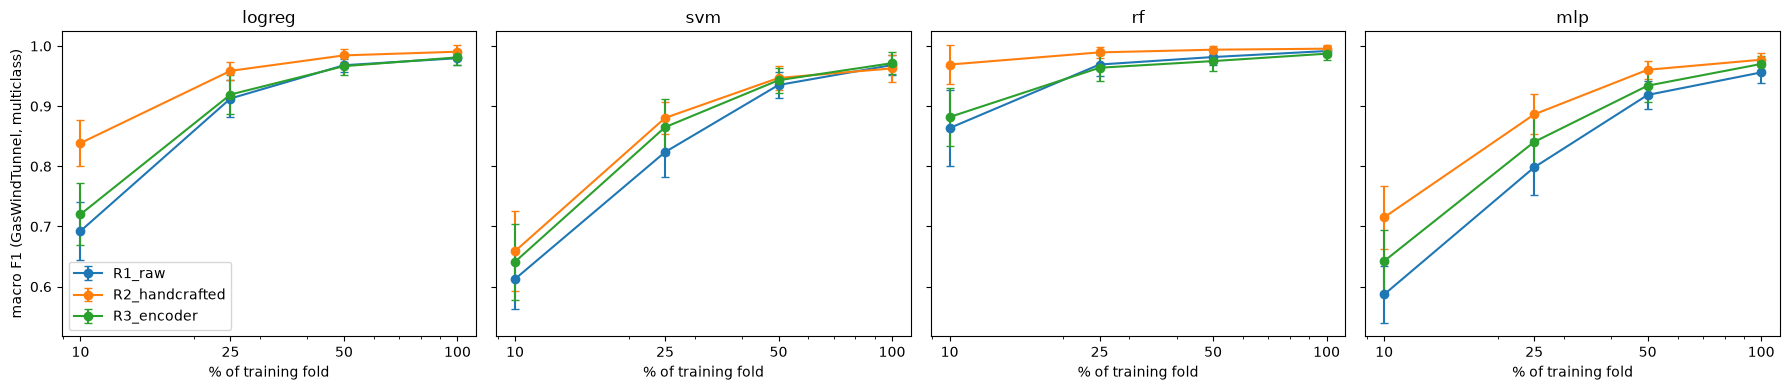

train_fraction          0.10   0.25   0.50   1.00
rep            head                              
R1_raw         logreg  0.692  0.913  0.968  0.980
               mlp     0.587  0.798  0.919  0.956
               rf      0.864  0.969  0.982  0.992
               svm     0.613  0.824  0.935  0.968
R2_handcrafted logreg  0.839  0.959  0.984  0.991
               mlp     0.715  0.886  0.960  0.977
               rf      0.969  0.989  0.994  0.996
               svm     0.659  0.880  0.947  0.963
R3_encoder     logreg  0.720  0.919  0.966  0.981
               mlp     0.642  0.841  0.934  0.970
               rf      0.882  0.964  0.975  0.987
               svm     0.641  0.865  0.943  0.971

In [4]:
full = pd.concat([pd.read_csv(ROOT / f"results/{n}.csv") for n in ["01a_gwt_raw", "02b_gwt_handcrafted", "03a_gwt_encoder"]])
full = full[full["task"] == TASK]
allf = pd.concat([scores, full], ignore_index=True)
curve = allf.groupby(["head", "rep", "train_fraction"])["macro_f1"].agg(["mean", "std"]).reset_index()

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, head in zip(axes, ["logreg", "svm", "rf", "mlp"]):
    for rep in ["R1_raw", "R2_handcrafted", "R3_encoder"]:
        c = curve[(curve["head"] == head) & (curve["rep"] == rep)]
        ax.errorbar(c["train_fraction"] * 100, c["mean"], yerr=c["std"], marker="o", capsize=3, label=rep)
    ax.set(xscale="log", xticks=[10, 25, 50, 100], xticklabels=["10", "25", "50", "100"],
           xlabel="% of training fold", title=head)
axes[0].set_ylabel("macro F1 (GasWindTunnel, multiclass)")
axes[0].legend()
plt.tight_layout()
plt.savefig(FIG / "04b_label_efficiency.png", dpi=150)
plt.show()
curve.pivot_table(index=["rep", "head"], columns="train_fraction", values="mean").round(3)

## Colab: save the outputs
Colab deletes everything when the session ends. This zips `results/` and `report/` into `outputs_<notebook>.zip`,
copies it to your Google Drive (`MyDrive/gas-repr-guide/`) and downloads it. On a laptop it does nothing.

In [5]:
if IN_COLAB:
    out_zip = shutil.make_archive(f"/content/outputs_04b_label_efficiency", "zip", REPO, "results")
    shutil.make_archive(f"/content/report_04b_label_efficiency", "zip", REPO, "report")
    files_out = [out_zip, f"/content/report_04b_label_efficiency.zip"]
    print(files_out)
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        out_dir = "/content/drive/MyDrive/gas-repr-guide"
        os.makedirs(out_dir, exist_ok=True)
        for f in files_out:
            shutil.copy(f, out_dir)
        print("copied to", out_dir)
    except Exception as e:
        print("Drive copy failed:", e)
    from google.colab import files
    for f in files_out:
        files.download(f)